In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("car.csv")
df

,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0
...,...,...,...,...,...,...,...,...,...
296,city,2016,9.50,11.60,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.00,5.90,60000,Petrol,Dealer,Manual,0
298,city,2009,3.35,11.00,87934,Petrol,Dealer,Manual,0
299,city,2017,11.50,12.50,9000,Diesel,Dealer,Manual,0


In [3]:
df.corr(numeric_only=True)

,Year,Selling_Price,Present_Price,Kms_Driven,Owner
Year,1.000000,0.236141,-0.047584,-0.524342,-0.182104
Selling_Price,0.236141,1.000000,0.878983,0.029187,-0.088344
Present_Price,-0.047584,0.878983,1.000000,0.203647,0.008057
Kms_Driven,-0.524342,0.029187,0.203647,1.000000,0.089216
Owner,-0.182104,-0.088344,0.008057,0.089216,1.000000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


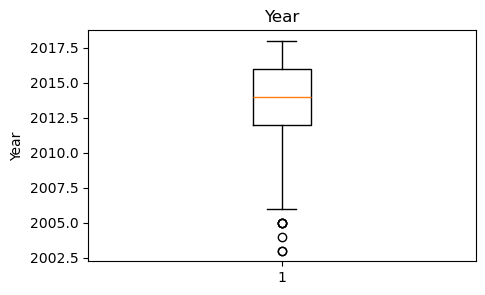

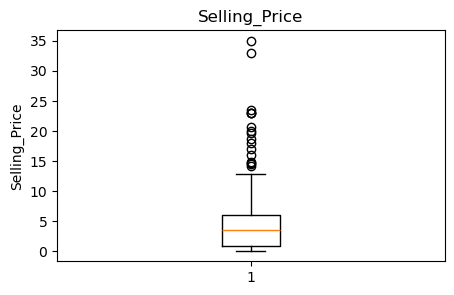

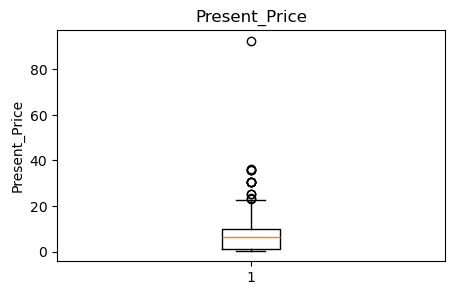

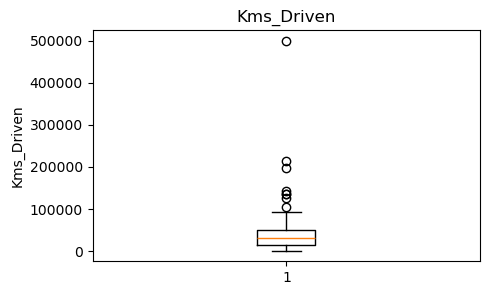

In [5]:
columns= ["Year", "Selling_Price", "Present_Price", "Kms_Driven"]

for col in columns:
    plt.figure(figsize=(5,3))
    plt.boxplot(df[col])
    plt.title(col)
    plt.ylabel(col)
    plt.show()

In [6]:
numeric_cols = ["Year", "Selling_Price", "Present_Price", "Kms_Driven"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

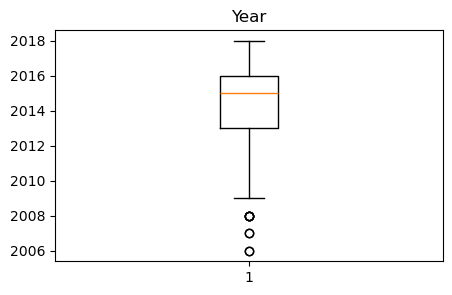

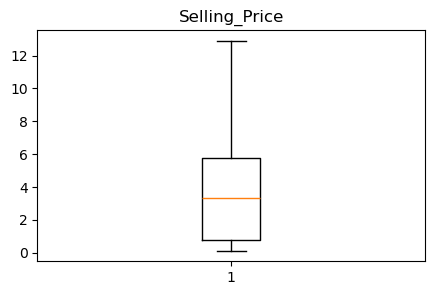

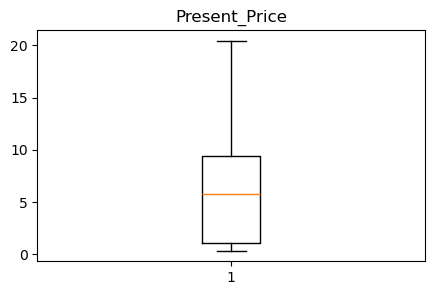

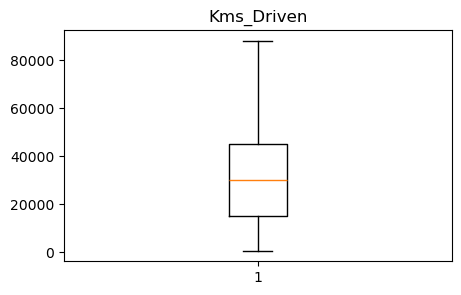

In [7]:
for col in numeric_cols:
    plt.figure(figsize=(5,3))
    plt.boxplot(df[col])
    plt.title(col)
    plt.show()

In [8]:
X = df.drop(columns=["Selling_Price"])
y = df["Selling_Price"]

print(X.dtypes)

Car_Name          object
Year               int64
Present_Price    float64
Kms_Driven         int64
Fuel_Type         object
Seller_Type       object
Transmission      object
Owner              int64
dtype: object


In [9]:
le = LabelEncoder()
df["Car_Name"] = le.fit_transform(df["Car_Name"])
df["Fuel_Type"] = le.fit_transform(df["Fuel_Type"])
df["Seller_Type"] = le.fit_transform(df["Seller_Type"])
df["Transmission"] = le.fit_transform(df["Transmission"])

In [10]:
X = df.drop(columns=["Selling_Price"])
y = df["Selling_Price"]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
poly = PolynomialFeatures(degree=2)

In [13]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [17]:

model = LinearRegression()
model.fit(X_train_poly, y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [19]:
y_pred = model.predict(X_test_poly)
y_pred

array([ 2.62439504,  0.53009013,  1.47968514,  0.26203848,  4.08354109,
        0.32634134,  2.77113137,  1.96049078, -0.3321146 ,  8.66631226,
        3.42769331, 12.36352973,  7.95237893,  1.08690603,  0.31875024,
        6.4162529 ,  8.44107304,  0.42225355,  0.7326884 ,  2.89327836,
        4.69787988,  3.72893466,  5.26711711,  1.89521987,  4.98316029,
        6.4873732 ,  4.55920666,  3.18800498,  0.65590728,  2.86219657,
        0.48382462,  4.16620521,  0.50885344,  4.73403457,  9.26952378,
        5.57272213,  0.49143435,  3.49730037,  0.43215998,  0.3867748 ,
        2.85847106,  0.25569417,  4.50794686,  3.47592241,  1.35066148,
        3.68793218,  0.73086342,  5.21527914,  1.21442678,  2.7208736 ,
        9.04126152,  0.45210264,  3.77638377,  4.33022734,  0.34853239])

In [15]:
for i in range(1, 10):
    poly = PolynomialFeatures(degree = i)
    poly_train_X = poly.fit_transform(X_train)
    poly_test_X = poly.transform(X_test)
    model = LinearRegression()
    model.fit(poly_train_X,y_train)
    y_pred = model.predict(poly_test_X)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse**0.5
    r2 = r2_score(y_test, y_pred)
    print("mae : ", mae)
    print("mse : ", mse)
    print("rmse : ", rmse)
    print("r2 : ", r2)
    print("="*30)

mae :  0.5660276192240469
mse :  0.610012469666285
rmse :  0.7810329504356939
r2 :  0.9258751011791512
mae :  0.45176983697925677
mse :  0.37485583499096553
rmse :  0.6122547141435217
r2 :  0.954449864186693
mae :  0.5921636876176232
mse :  0.7681599614398389
rmse :  0.8764473523491522
r2 :  0.9066580074156438
mae :  0.6298079558293054
mse :  0.7471187875698996
rmse :  0.864360334333951
r2 :  0.9092147992219398
mae :  0.6366343962693239
mse :  1.4421816010205286
rmse :  1.2009086564016969
r2 :  0.8247551147349197
mae :  0.6626278109450865
mse :  1.1954767852697632
rmse :  1.093378610212292
r2 :  0.8547331404565016
mae :  1.35824698586804
mse :  3.46529126932191
rmse :  1.8615292824239724
r2 :  0.5789194852626895
mae :  2.0029892273050147
mse :  9.19628232913041
rmse :  3.0325372758022957
r2 :  -0.11747469284958933
mae :  1.8649510228171384
mse :  5.2085483932334515
rmse :  2.2822244397152205
r2 :  0.36708978611021537
